In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/manishasharma005/construction-data-visualization/construction_project_dataset_simulated.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay
)

df = pd.read_csv("/kaggle/input/datasets/manishasharma005/construction-data-visualization/construction_project_dataset_simulated.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())

     Project_Type Location  Project_Size  Planned_Duration_Days  \
0  Infrastructure    Urban             5                  106.9   
1  Infrastructure    Rural             4                  111.1   
2  Infrastructure    Urban             7                  128.8   
3      Commercial    Urban             4                   85.3   
4      Commercial    Urban            10                  219.0   

   Actual_Duration_Days  Planned_Cost_INR  Actual_Cost_INR  Workers  \
0                 129.9        14766402.0       17193300.0      149   
1                 143.1         8209433.0        7959432.0      117   
2                 151.8        15830775.0       16365198.0      143   
3                 109.3         8342885.0        9138216.0       28   
4                 233.0        18660928.0       23881840.0       72   

   Equipment_Hours  Material_Cost_INR  Labor_Cost_INR  Delay_Days  \
0           2063.0          8619837.0       2826317.0          23   
1           1366.0          5874

In [4]:
df = df.drop_duplicates()

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

df["Cost_Overrun_Pct"] = (
    (df["Actual_Cost_INR"] - df["Planned_Cost_INR"])
    / df["Planned_Cost_INR"]
) * 100

df["Duration_Variance_Days"] = (
    df["Actual_Duration_Days"] - df["Planned_Duration_Days"]
)

df["Delay_Flag"] = (df["Delay_Days"] > 0).astype(int)

print(df.describe())

       Project_Size  Planned_Duration_Days  Actual_Duration_Days  \
count    200.000000             200.000000            200.000000   
mean       5.265000             119.794000            134.854000   
std        2.746359              52.274345             55.179235   
min        1.000000              30.000000             20.000000   
25%        3.000000              79.950000             89.950000   
50%        5.000000             113.950000            134.150000   
75%        8.000000             163.100000            181.125000   
max       10.000000             228.300000            248.300000   

       Planned_Cost_INR  Actual_Cost_INR    Workers  Equipment_Hours  \
count      2.000000e+02     2.000000e+02  200.00000       200.000000   
mean       1.197033e+07     1.277805e+07   83.05000      1847.055000   
std        5.804263e+06     6.414017e+06   40.24707       558.228715   
min        1.050167e+06     1.119785e+06   15.00000       400.000000   
25%        7.397539e+06    

In [5]:
print("Total projects:", len(df))
print("Delayed projects:", df["Delay_Flag"].sum())

print(
    "Delay percentage:",
    round(df["Delay_Flag"].mean() * 100, 2), "%"
)

print(
    "Average delay:",
    round(df.loc[df["Delay_Days"] > 0, "Delay_Days"].mean(), 2),
    "days"
)

print(
    "Average cost variance:",
    round(df["Cost_Overrun_Pct"].mean(), 2), "%"
)

print(
    "Average quality score:",
    round(df["Quality_Score"].mean(), 2)
)

Total projects: 200
Delayed projects: 173
Delay percentage: 86.5 %
Average delay: 18.28 days
Average cost variance: 6.29 %
Average quality score: 84.03


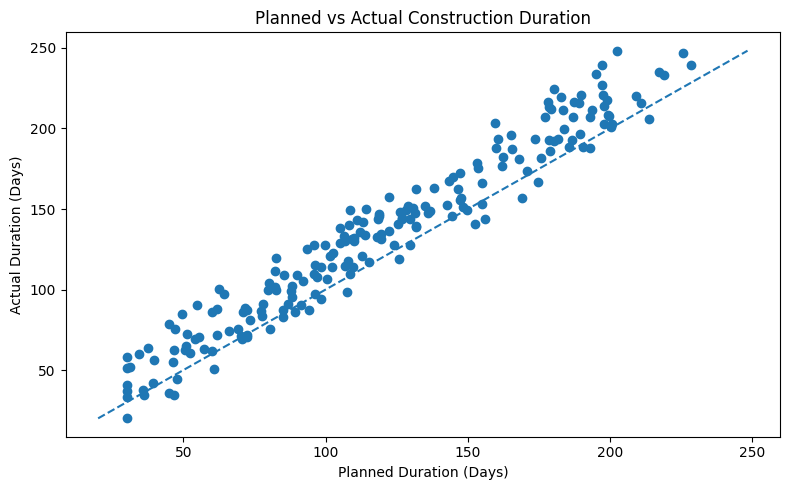

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Planned_Duration_Days"],
    df["Actual_Duration_Days"]
)

minimum = min(
    df["Planned_Duration_Days"].min(),
    df["Actual_Duration_Days"].min()
)

maximum = max(
    df["Planned_Duration_Days"].max(),
    df["Actual_Duration_Days"].max()
)

plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")

plt.xlabel("Planned Duration (Days)")
plt.ylabel("Actual Duration (Days)")
plt.title("Planned vs Actual Construction Duration")
plt.tight_layout()
plt.show()

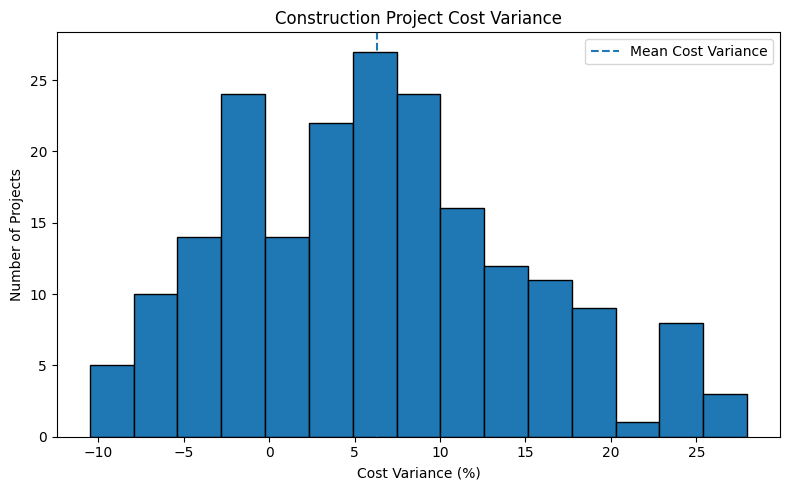

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(df["Cost_Overrun_Pct"], bins=15, edgecolor="black")

plt.axvline(
    df["Cost_Overrun_Pct"].mean(),
    linestyle="--",
    label="Mean Cost Variance"
)

plt.xlabel("Cost Variance (%)")
plt.ylabel("Number of Projects")
plt.title("Construction Project Cost Variance")
plt.legend()
plt.tight_layout()
plt.show()

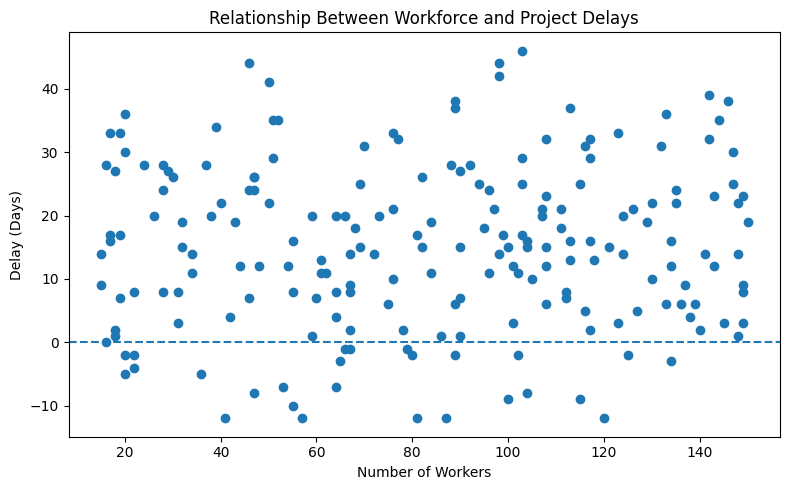

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Workers"], df["Delay_Days"])
plt.axhline(0, linestyle="--")

plt.xlabel("Number of Workers")
plt.ylabel("Delay (Days)")
plt.title("Relationship Between Workforce and Project Delays")
plt.tight_layout()
plt.show()

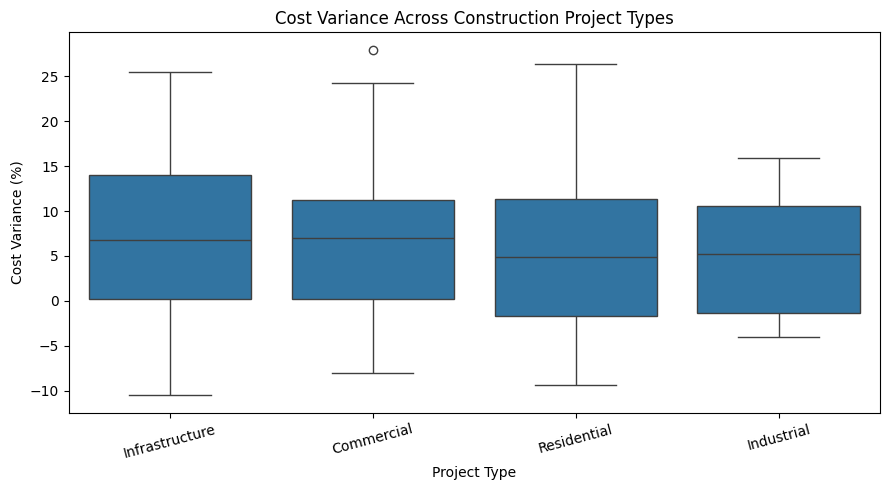

In [9]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Project_Type",
    y="Cost_Overrun_Pct"
)

plt.xlabel("Project Type")
plt.ylabel("Cost Variance (%)")
plt.title("Cost Variance Across Construction Project Types")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

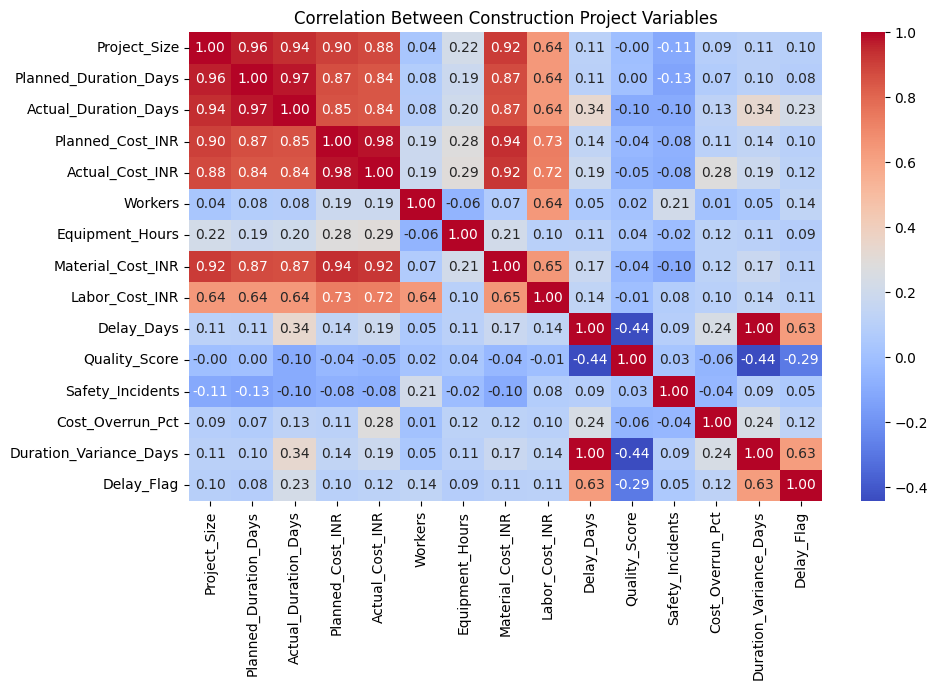

In [10]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Construction Project Variables")
plt.tight_layout()
plt.show()

In [11]:
features = [
    "Planned_Cost_INR",
    "Material_Cost_INR",
    "Labor_Cost_INR",
    "Workers",
    "Equipment_Hours",
    "Project_Size",
    "Project_Type",
    "Location"
]

X = df[features]
y = df["Actual_Cost_INR"]

numeric_features = [
    "Planned_Cost_INR",
    "Material_Cost_INR",
    "Labor_Cost_INR",
    "Workers",
    "Equipment_Hours",
    "Project_Size"
]

categorical_features = ["Project_Type", "Location"]

preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("R2 Score:", round(r2_score(y_test, predictions), 3))
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))

R2 Score: 0.956
MAE: 1117057.61
RMSE: 1493286.43


In [12]:
delay_features = [
    "Project_Type",
    "Location",
    "Project_Size",
    "Planned_Duration_Days",
    "Planned_Cost_INR",
    "Workers",
    "Equipment_Hours",
    "Material_Cost_INR",
    "Labor_Cost_INR",
    "Safety_Incidents"
]

X = df[delay_features]
y = df["Delay_Flag"]

numeric_features = [
    col for col in delay_features
    if col not in ["Project_Type", "Location"]
]

categorical_features = ["Project_Type", "Location"]

preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

delay_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

delay_model.fit(X_train, y_train)

delay_predictions = delay_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, delay_predictions), 3))
print("Precision:", round(precision_score(y_test, delay_predictions, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, delay_predictions, zero_division=0), 3))
print("F1 Score:", round(f1_score(y_test, delay_predictions, zero_division=0), 3))

Accuracy: 0.6
Precision: 0.897
Recall: 0.605
F1 Score: 0.722


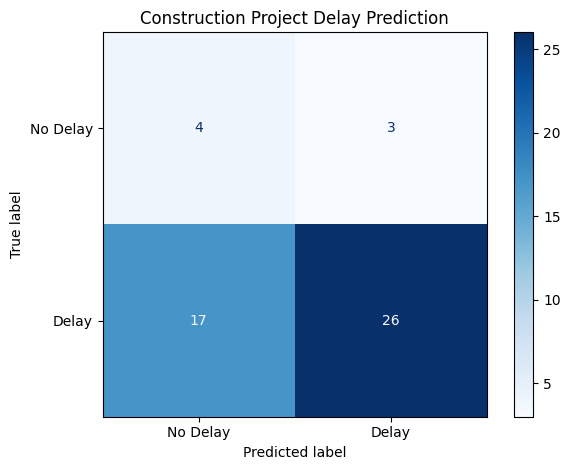

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    delay_predictions,
    display_labels=["No Delay", "Delay"],
    cmap="Blues"
)

plt.title("Construction Project Delay Prediction")
plt.tight_layout()
plt.show()

In [14]:
df.to_csv(
    "construction_project_analysis.csv",
    index=False
)

print("Analysis dataset exported successfully.")

Analysis dataset exported successfully.
